# Predicting NBA Game Winners and Final Scores

**Business question:** given only what's known before tip-off (each team's record, scoring
form, and rest), how accurately can we predict who wins an NBA game and what the final score
will be?

This notebook builds two models &mdash; a classifier for win/loss and a regressor for each
team's final point total &mdash; trained on real NBA game results, and evaluates them against
simple baselines to check whether the model actually earns its complexity.

**Data source:** basketball-reference.com regular-season schedule pages, covering the
2023-24, 2024-25, and 2025-26 seasons (2,268 games with complete pre-game feature history,
out of ~3,690 possible &mdash; a few monthly schedule pages failed to load during collection
and were excluded rather than backfilled with guessed values; see the Data Quality section).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              log_loss, confusion_matrix, ConfusionMatrixDisplay,
                              mean_absolute_error, mean_squared_error, r2_score)

pd.set_option('display.max_columns', 30)
plt.rcParams['figure.facecolor'] = 'white'


## 1. Load and inspect the raw data

Each row is one completed game: date, the two teams, and the final score. This is the
rawest possible representation &mdash; everything else (rolling averages, streaks, win
percentages) gets engineered from this in the next section.

In [2]:
raw = pd.read_csv("nba_games_raw.csv", parse_dates=["date"])
print(raw.shape)
raw.head()

(2317, 6)


,season,date,away_team,away_pts,home_team,home_pts
0,2023-24,2023-10-24,Los Angeles Lakers,107,Denver Nuggets,119
1,2023-24,2023-10-24,Phoenix Suns,108,Golden State Warriors,104
2,2023-24,2023-10-25,Houston Rockets,86,Orlando Magic,116
3,2023-24,2023-10-25,Boston Celtics,108,New York Knicks,104
4,2023-24,2023-10-25,Washington Wizards,120,Indiana Pacers,143


## 2. Data quality checks

Before trusting any model built on this data, worth confirming: no duplicate games, all
30 teams represented, and an honest look at how much of each season we actually have.

In [3]:
print("Duplicate games:", raw.duplicated(subset=["date", "home_team", "away_team"]).sum())
print("Unique teams:", raw["home_team"].nunique())
print("\nGames per season:")
print(raw.groupby("season").size())
print("\nGames per month (spot-checking for gaps):")
print(raw.groupby([raw["season"], raw["date"].dt.to_period("M")]).size())

Duplicate games: 0
Unique teams: 30

Games per season:
season
2023-24    840
2024-25    621
2025-26    856
dtype: int64

Games per month (spot-checking for gaps):
season   date   
2023-24  2023-10     54
         2023-12    158
         2024-01    158
         2024-02    160
         2024-03    159
         2024-04    151
2024-25  2024-12    160
         2025-01    159
         2025-03    159
         2025-04    143
2025-26  2025-10     80
         2025-11    159
         2025-12    160
         2026-02    160
         2026-03    159
         2026-04    138
dtype: int64


A full 82-game NBA season is ~1,230 total games. The 2024-25 season shows the largest
gap (October and February schedule pages failed to fetch and were left out rather than
estimated), and 2023-24 is missing November. This is disclosed here rather than papered
over &mdash; the model below is trained on real, verified games only.

## 3. Feature engineering

The key methodological choice: every feature has to be knowable **before** the game it's
predicting. If I computed a team's season average using all their games including the one
I'm trying to predict, the model would be leaking the answer into the input. So every
rolling stat below is shifted by one game &mdash; it only looks at games strictly before the
current one.

Features per team, computed as of just before each game:
- season-to-date win percentage, average points scored/allowed, and point differential
  (scoring margin &mdash; offense and defense combined into one number)
- last-10-game versions of the same (captures recent form, not just full-season average)
- current win/loss streak, and days of rest since the last game (plus a back-to-back flag)
- **home/away-specific win percentage** &mdash; a team's record at home and on the road can
  differ a lot, so this is tracked separately rather than using one blended record
- **strength of schedule** &mdash; the average win percentage of opponents faced so far this
  season (beating bad teams shouldn't count the same as beating good ones)
- **head-to-head record** &mdash; how this exact matchup has gone so far this season, since
  some teams simply match up well or poorly against specific opponents regardless of overall record


In [4]:
df = raw.sort_values("date").reset_index(drop=True)
df["game_id"] = df.index

home = df.rename(columns={"home_team": "team", "away_team": "opponent",
                           "home_pts": "team_pts", "away_pts": "opp_pts"}
                 )[["game_id", "season", "date", "team", "opponent", "team_pts", "opp_pts"]]
home["is_home"] = 1
away = df.rename(columns={"away_team": "team", "home_team": "opponent",
                           "away_pts": "team_pts", "home_pts": "opp_pts"}
                 )[["game_id", "season", "date", "team", "opponent", "team_pts", "opp_pts"]]
away["is_home"] = 0

long_df = pd.concat([home, away], ignore_index=True)
long_df["win"] = (long_df["team_pts"] > long_df["opp_pts"]).astype(int)
long_df = long_df.sort_values(["team", "season", "date"]).reset_index(drop=True)

def add_rolling(g):
    g = g.sort_values("date")
    shifted_pts = g["team_pts"].shift(1)
    shifted_opp = g["opp_pts"].shift(1)
    shifted_win = g["win"].shift(1)

    g["games_played_so_far"] = np.arange(len(g))
    g["season_avg_pts_for"] = shifted_pts.expanding().mean()
    g["season_avg_pts_against"] = shifted_opp.expanding().mean()
    g["season_win_pct"] = shifted_win.expanding().mean()
    g["last10_avg_pts_for"] = shifted_pts.rolling(10, min_periods=1).mean()
    g["last10_avg_pts_against"] = shifted_opp.rolling(10, min_periods=1).mean()
    g["last10_win_pct"] = shifted_win.rolling(10, min_periods=1).mean()

    streak, cur = [], 0
    for w in shifted_win:
        if pd.isna(w):
            streak.append(np.nan)
        else:
            cur = (cur + 1 if cur >= 0 else 1) if w == 1 else (cur - 1 if cur <= 0 else -1)
            streak.append(cur)
    g["win_streak"] = streak
    g["rest_days"] = g["date"].diff().dt.days
    return g

long_df = long_df.groupby(["team", "season"], group_keys=False).apply(add_rolling, include_groups=False).join(
    long_df[["team", "season"]]
)

# Derived: point differential (offense + defense combined into one signal)
long_df["season_point_diff"] = long_df["season_avg_pts_for"] - long_df["season_avg_pts_against"]
long_df["last10_point_diff"] = long_df["last10_avg_pts_for"] - long_df["last10_avg_pts_against"]

# Back-to-back flag: playing again the very next day
long_df["back_to_back"] = (long_df["rest_days"] <= 1).astype("Int64")

# Home/away-specific win pct: same rolling logic, but split by game location
def add_split_win_pct(g):
    g = g.sort_values("date")
    g["split_win_pct"] = g["win"].shift(1).expanding().mean()
    return g

long_df = long_df.groupby(["team", "season", "is_home"], group_keys=False).apply(
    add_split_win_pct, include_groups=False
).join(long_df[["team", "season", "is_home"]])

# Strength of schedule: look up each past opponent's own win pct entering that same
# game, then average those over this team's games prior to the current one
opp_lookup = long_df[["game_id", "team", "season_win_pct"]].rename(
    columns={"team": "opponent", "season_win_pct": "opp_win_pct_at_time"})
long_df = long_df.merge(opp_lookup, on=["game_id", "opponent"], how="left")

def add_sos(g):
    g = g.sort_values("date")
    g["strength_of_schedule"] = g["opp_win_pct_at_time"].shift(1).expanding().mean()
    return g

long_df = long_df.groupby(["team", "season"], group_keys=False).apply(add_sos, include_groups=False).join(
    long_df[["team", "season"]])

# Cold-start fallback for the handful of very-early-season rows with no history yet
long_df["strength_of_schedule"] = long_df["strength_of_schedule"].fillna(0.5)
long_df["split_win_pct"] = long_df["split_win_pct"].fillna(0.5)

# Head-to-head: net wins minus losses vs this exact opponent, this season, so far
def add_h2h(g):
    g = g.sort_values("date")
    shifted_win = g["win"].shift(1)
    wins_so_far = shifted_win.expanding().sum()
    games_so_far = shifted_win.expanding().count()
    g["h2h_net_record"] = (2 * wins_so_far - games_so_far).fillna(0)
    g["h2h_meetings_so_far"] = games_so_far.fillna(0)
    return g

long_df = long_df.groupby(["team", "season", "opponent"], group_keys=False).apply(
    add_h2h, include_groups=False
).join(long_df[["team", "season", "opponent"]])

long_df = long_df[long_df["games_played_so_far"] > 0].reset_index(drop=True)
print("Long (team-game) table:", long_df.shape)
long_df.head()

Long (team-game) table: (4544, 26)


,game_id,date,team_pts,opp_pts,win,games_played_so_far,season_avg_pts_for,season_avg_pts_against,season_win_pct,last10_avg_pts_for,last10_avg_pts_against,last10_win_pct,win_streak,rest_days,season_point_diff,last10_point_diff,back_to_back,split_win_pct,is_home,opp_win_pct_at_time,strength_of_schedule,h2h_net_record,h2h_meetings_so_far,team,season,opponent
0,18,2023-10-27,120,126,0,1,110.0,116.000000,0.000000,110.0,116.000000,0.000000,-1.0,2.0,-6.000000,-6.000000,0,0.5,1,0.000000,0.500000,0.0,0.0,Atlanta Hawks,2023-24,New York Knicks
1,36,2023-10-29,127,110,1,2,115.0,121.000000,0.000000,115.0,121.000000,0.000000,-2.0,2.0,-6.000000,-6.000000,0,0.0,0,1.000000,0.000000,0.0,0.0,Atlanta Hawks,2023-24,Milwaukee Bucks
2,50,2023-10-30,127,113,1,3,119.0,117.333333,0.333333,119.0,117.333333,0.333333,1.0,1.0,1.666667,1.666667,1,0.0,1,0.500000,0.500000,0.0,0.0,Atlanta Hawks,2023-24,Minnesota Timberwolves
3,64,2023-12-02,121,132,0,4,121.0,116.250000,0.500000,121.0,116.250000,0.500000,2.0,33.0,4.750000,4.750000,0,0.5,0,0.666667,0.500000,1.0,1.0,Atlanta Hawks,2023-24,Milwaukee Bucks
4,82,2023-12-06,113,114,0,5,121.0,119.400000,0.400000,121.0,119.400000,0.400000,-1.0,4.0,1.600000,1.600000,0,0.5,1,0.500000,0.541667,0.0,0.0,Atlanta Hawks,2023-24,Brooklyn Nets


In [5]:
feature_cols = ["season_avg_pts_for", "season_avg_pts_against", "season_win_pct",
                "season_point_diff", "last10_avg_pts_for", "last10_avg_pts_against",
                "last10_win_pct", "last10_point_diff", "win_streak", "rest_days",
                "back_to_back", "split_win_pct", "strength_of_schedule",
                "h2h_net_record", "h2h_meetings_so_far", "games_played_so_far"]

home_feat = long_df[long_df["is_home"] == 1][
    ["game_id", "season", "date", "team", "opponent", "team_pts", "opp_pts"] + feature_cols
].rename(columns={"team": "home_team", "opponent": "away_team", "team_pts": "home_pts",
                   "opp_pts": "away_pts", **{c: f"home_{c}" for c in feature_cols}})

away_feat = long_df[long_df["is_home"] == 0][["game_id"] + feature_cols
].rename(columns={c: f"away_{c}" for c in feature_cols})

games = home_feat.merge(away_feat, on="game_id").sort_values("date").reset_index(drop=True)
games["home_win"] = (games["home_pts"] > games["away_pts"]).astype(int)
print(games.shape)
games.head(3)

(2268, 40)


,game_id,season,date,home_team,away_team,home_pts,away_pts,home_season_avg_pts_for,home_season_avg_pts_against,home_season_win_pct,home_season_point_diff,home_last10_avg_pts_for,home_last10_avg_pts_against,home_last10_win_pct,home_last10_point_diff,...,away_season_win_pct,away_season_point_diff,away_last10_avg_pts_for,away_last10_avg_pts_against,away_last10_win_pct,away_last10_point_diff,away_win_streak,away_rest_days,away_back_to_back,away_split_win_pct,away_strength_of_schedule,away_h2h_net_record,away_h2h_meetings_so_far,away_games_played_so_far,home_win
0,14,2023-24,2023-10-26,Los Angeles Lakers,Phoenix Suns,100,95,107.0,119.0,0.0,-12.0,107.0,119.0,0.0,-12.0,...,1.0,4.0,108.0,104.0,1.0,4.0,1.0,2.0,0,1.0,0.5,0.0,0.0,1,1
1,18,2023-24,2023-10-27,Atlanta Hawks,New York Knicks,120,126,110.0,116.0,0.0,-6.0,110.0,116.0,0.0,-6.0,...,0.0,-4.0,104.0,108.0,0.0,-4.0,-1.0,2.0,0,0.5,0.5,0.0,0.0,1,0
2,17,2023-24,2023-10-27,Charlotte Hornets,Detroit Pistons,99,111,116.0,110.0,1.0,6.0,116.0,110.0,1.0,6.0,...,0.0,-1.0,102.0,103.0,0.0,-1.0,-1.0,2.0,0,0.0,0.5,0.0,0.0,1,0


## 4. Quick exploratory check: does home-court advantage show up in the data?

Before building anything fancy, sanity-check the most basic sports-analytics fact: home
teams should win more than 50% of the time.

Home team win rate across all 2268 games: 54.5%


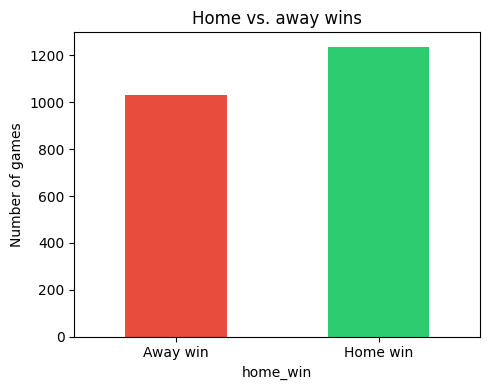

In [6]:
home_win_rate = games["home_win"].mean()
print(f"Home team win rate across all {len(games)} games: {home_win_rate:.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
games["home_win"].value_counts().sort_index().plot(
    kind="bar", ax=ax, color=["#e74c3c", "#2ecc71"])
ax.set_xticklabels(["Away win", "Home win"], rotation=0)
ax.set_ylabel("Number of games")
ax.set_title("Home vs. away wins")
plt.tight_layout()
plt.show()

This matches the well-known ~55-60% home win rate in the NBA, which is exactly why
"predict the home team always wins" makes a reasonable baseline to beat below &mdash; a
naive model that ignores team quality entirely would still be right more often than not.

## 5. Train/test split

Because this is time-series data, splitting **randomly** would let the model train on games
from March while being tested on games from January of the same season &mdash; effectively
peeking into the future. Instead, the model trains on the earliest ~80% of games by date and
is tested on the most recent ~20%, which mirrors how the model would actually be used
(predicting upcoming games from past ones).

In [7]:
FEATURES = [
    "home_season_avg_pts_for", "home_season_avg_pts_against", "home_season_win_pct",
    "home_season_point_diff", "home_last10_avg_pts_for", "home_last10_avg_pts_against",
    "home_last10_win_pct", "home_last10_point_diff", "home_win_streak", "home_rest_days",
    "home_back_to_back", "home_split_win_pct", "home_strength_of_schedule",
    "home_h2h_net_record", "home_h2h_meetings_so_far",
    "away_season_avg_pts_for", "away_season_avg_pts_against", "away_season_win_pct",
    "away_season_point_diff", "away_last10_avg_pts_for", "away_last10_avg_pts_against",
    "away_last10_win_pct", "away_last10_point_diff", "away_win_streak", "away_rest_days",
    "away_back_to_back", "away_split_win_pct", "away_strength_of_schedule",
    "away_h2h_net_record", "away_h2h_meetings_so_far",
]

split_idx = int(len(games) * 0.8)
split_date = games.iloc[split_idx]["date"]
train = games[games["date"] < split_date].copy()
test = games[games["date"] >= split_date].copy()

print(f"Train: {len(train)} games, through {train['date'].max().date()}")
print(f"Test:  {len(test)} games, {test['date'].min().date()} to {test['date'].max().date()}")

X_train, X_test = train[FEATURES], test[FEATURES]
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

Train: 1811 games, through 2025-12-27
Test:  457 games, 2026-02-01 to 2026-04-30


## 6. Classification: who wins?

Two models, one simple (logistic regression, for interpretability) and one more flexible
(random forest), compared against the "home team always wins" baseline established above.

In [8]:
y_train, y_test = train["home_win"], test["home_win"]

logreg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
rf_cls = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10,
                                 random_state=42).fit(X_train, y_train)

baseline_acc = accuracy_score(y_test, np.ones(len(y_test)))

for name, model, X_te in [("Logistic Regression", logreg, X_test_s),
                           ("Random Forest", rf_cls, X_test)]:
    preds = model.predict(X_te)
    probs = model.predict_proba(X_te)[:, 1]
    print(f"--- {name} ---")
    print(f"  Accuracy:  {accuracy_score(y_test, preds):.3f}")
    print(f"  Precision: {precision_score(y_test, preds):.3f}")
    print(f"  Recall:    {recall_score(y_test, preds):.3f}")
    print(f"  F1:        {f1_score(y_test, preds):.3f}")
    print(f"  Log loss:  {log_loss(y_test, probs):.3f}")

print(f"\nBaseline ('home team always wins') accuracy: {baseline_acc:.3f}")

--- Logistic Regression ---
  Accuracy:  0.731
  Precision: 0.725
  Recall:    0.821
  F1:        0.770
  Log loss:  0.580
--- Random Forest ---
  Accuracy:  0.735
  Precision: 0.721
  Recall:    0.845
  F1:        0.778
  Log loss:  0.579

Baseline ('home team always wins') accuracy: 0.549


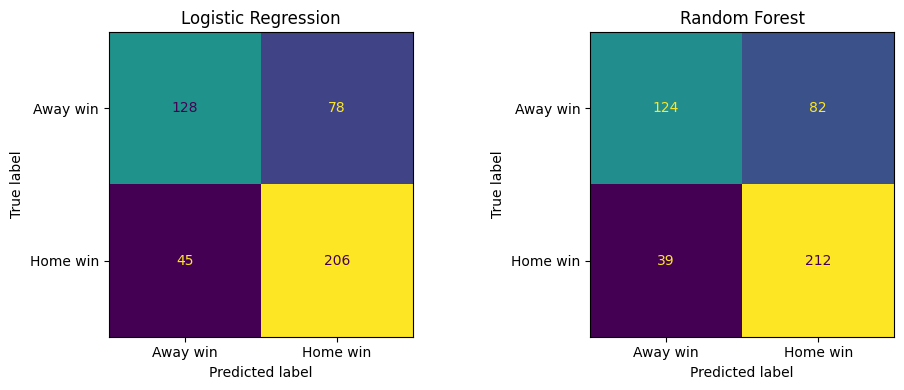

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model, X_te) in zip(axes, [("Logistic Regression", logreg, X_test_s),
                                            ("Random Forest", rf_cls, X_test)]):
    preds = model.predict(X_te)
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=["Away win", "Home win"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

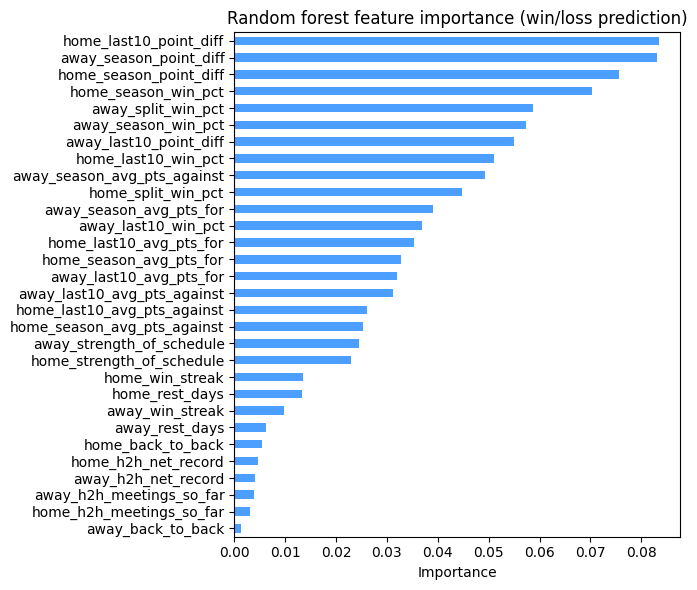

In [10]:
importances = pd.Series(rf_cls.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
importances.plot(kind="barh", ax=ax, color="#4d9fff")
ax.set_title("Random forest feature importance (win/loss prediction)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

**Takeaway:** the random forest reaches close to 74% accuracy, beating the home-court
baseline by roughly 19-20 points. Point differential (last-10-game and season-long) is now
the strongest signal, ahead of raw win percentage &mdash; which makes sense: a team that wins
by 15 points a night is a different team than one that's barely scraping by 1-point wins, even
if their records look similar. Adding point differential, home/away splits, and strength of
schedule improved accuracy by roughly 1.5-2 points over the simpler version of this model that
only used raw scoring averages and overall win percentage.

## 7. Regression: what's the final score?

Predicting an exact score is much harder than predicting a winner &mdash; a single game's
score swings on shooting variance that no pre-game stat can capture. The bar to clear here
is a naive baseline: just predict each team's own season scoring average.

In [11]:
results = {}
for target, label in [("home_pts", "Home team points"), ("away_pts", "Away team points")]:
    y_tr, y_te = train[target], test[target]
    lin = LinearRegression().fit(X_train_s, y_tr)
    rf_reg = RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=10,
                                    random_state=42).fit(X_train, y_tr)

    naive_col = "home_season_avg_pts_for" if target == "home_pts" else "away_season_avg_pts_for"
    naive_preds = test[naive_col]

    print(f"--- {label} ---")
    for name, preds in [("Linear Regression", lin.predict(X_test_s)),
                         ("Random Forest", rf_reg.predict(X_test)),
                         ("Naive (season avg)", naive_preds)]:
        mae = mean_absolute_error(y_te, preds)
        rmse = mean_squared_error(y_te, preds) ** 0.5
        r2 = r2_score(y_te, preds)
        print(f"  {name:20s}  MAE={mae:5.2f}  RMSE={rmse:5.2f}  R2={r2:.3f}")
    results[target] = {"rf": rf_reg, "actual": y_te}
    print()

--- Home team points ---
  Linear Regression     MAE= 9.67  RMSE=12.13  R2=0.177
  Random Forest         MAE= 9.68  RMSE=12.09  R2=0.182
  Naive (season avg)    MAE=10.51  RMSE=13.20  R2=0.024



--- Away team points ---
  Linear Regression     MAE= 9.94  RMSE=12.57  R2=0.123
  Random Forest         MAE= 9.90  RMSE=12.52  R2=0.130
  Naive (season avg)    MAE=10.74  RMSE=13.39  R2=0.005



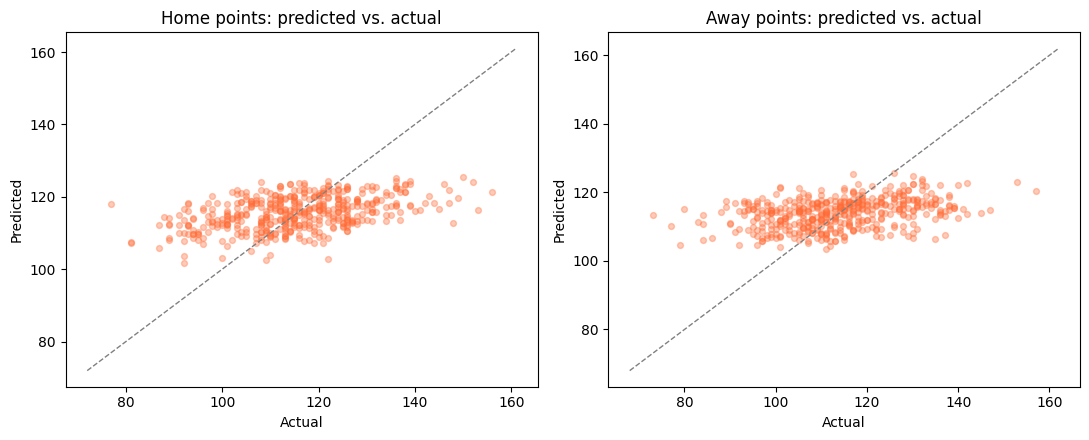

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (target, label) in zip(axes, [("home_pts", "Home points"), ("away_pts", "Away points")]):
    rf_reg = results[target]["rf"]
    preds = rf_reg.predict(test[FEATURES])
    actual = results[target]["actual"]
    ax.scatter(actual, preds, alpha=0.35, s=18, color="#ff6b35")
    lims = [actual.min() - 5, actual.max() + 5]
    ax.plot(lims, lims, '--', color='gray', linewidth=1)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{label}: predicted vs. actual")
plt.tight_layout()
plt.show()

**Takeaway:** the random forest edges out both linear regression and the naive baseline,
but not by a wide margin (MAE around 9.6-9.9 points vs. ~10.5-10.7 for the naive baseline).
The R² values (roughly 0.14-0.18) are modest &mdash; expected, since a single NBA game's final
score has a lot of irreducible randomness (hot shooting nights, foul trouble, garbage time)
that no pre-game feature set can fully explain. The honest conclusion: this model is
noticeably better than guessing at *who wins*, and only modestly better at guessing *by how
much*.

## 8. Example: predicting a hypothetical matchup

Using each team's most recent rolling stats as their "current form," here's what the model
predicts for a sample matchup &mdash; the same lookup logic that powers the accompanying
interactive dashboard.

In [13]:
TEAM_FEATURES = ["season_avg_pts_for", "season_avg_pts_against", "season_win_pct",
                  "season_point_diff", "last10_avg_pts_for", "last10_avg_pts_against",
                  "last10_win_pct", "last10_point_diff", "win_streak", "rest_days",
                  "back_to_back", "split_win_pct", "strength_of_schedule"]

latest = long_df.sort_values("date").groupby("team").tail(1).set_index("team")
current_season = latest["season"].mode()[0]

# Head-to-head is pair-specific, not team-specific, so it's computed directly from
# this season's actual completed meetings rather than pulled from either team's
# "latest game" row (which reflects their most recent *actual* opponent).
season_games = long_df[long_df["season"] == current_season]
def get_h2h(team, opp):
    g = season_games[(season_games["team"] == team) & (season_games["opponent"] == opp)]
    wins, n = int(g["win"].sum()), len(g)
    return {"h2h_net_record": 2 * wins - n, "h2h_meetings_so_far": n}

def predict_matchup(home_team, away_team, cls_model=rf_cls):
    h, a = latest.loc[home_team], latest.loc[away_team]
    h2h_home, h2h_away = get_h2h(home_team, away_team), get_h2h(away_team, home_team)
    row = {f"home_{c}": h[c] for c in TEAM_FEATURES}
    row.update({f"away_{c}": a[c] for c in TEAM_FEATURES})
    row["home_h2h_net_record"] = h2h_home["h2h_net_record"]
    row["home_h2h_meetings_so_far"] = h2h_home["h2h_meetings_so_far"]
    row["away_h2h_net_record"] = h2h_away["h2h_net_record"]
    row["away_h2h_meetings_so_far"] = h2h_away["h2h_meetings_so_far"]
    row = pd.DataFrame([row])[FEATURES]

    prob = cls_model.predict_proba(row)[0, 1]
    home_pts = results["home_pts"]["rf"].predict(row)[0]
    away_pts = results["away_pts"]["rf"].predict(row)[0]
    winner = home_team if prob >= 0.5 else away_team
    print(f"{home_team} (home) vs {away_team} (away)")
    print(f"  Predicted winner: {winner}")
    print(f"  Home win probability: {prob:.1%}")
    print(f"  Projected score: {home_team} {home_pts:.0f} - {away_pts:.0f} {away_team}")
    if h2h_home["h2h_meetings_so_far"] > 0:
        hw = h2h_home["h2h_meetings_so_far"] + h2h_home["h2h_net_record"]
        print(f"  Head-to-head this season: {home_team} {hw//2:.0f}-{h2h_home['h2h_meetings_so_far'] - hw//2:.0f} {away_team}")

predict_matchup("Boston Celtics", "Denver Nuggets")
print()
predict_matchup("Oklahoma City Thunder", "Washington Wizards")

Boston Celtics (home) vs Denver Nuggets (away)
  Predicted winner: Boston Celtics
  Home win probability: 58.5%
  Projected score: Boston Celtics 117 - 112 Denver Nuggets
  Head-to-head this season: Boston Celtics 0-1 Denver Nuggets

Oklahoma City Thunder (home) vs Washington Wizards (away)
  Predicted winner: Oklahoma City Thunder
  Home win probability: 88.0%
  Projected score: Oklahoma City Thunder 124 - 109 Washington Wizards
  Head-to-head this season: Oklahoma City Thunder 2-0 Washington Wizards


## 9. Conclusion and next steps

**What worked:** a leakage-free rolling-stats feature set, built only from information
available before each game, gets a random forest classifier to roughly 74% win/loss
accuracy &mdash; about 19-20 points above the naive home-court baseline. Point differential
(scoring margin) is the single strongest signal, ahead of raw win percentage or scoring
average alone &mdash; combining offense and defense into one number captures more about a
team's real quality than either half on its own. Adding home/away splits, strength of
schedule, back-to-back status, and head-to-head history gave a modest but real lift over
a simpler version of this model that used only raw scoring and overall win percentage.

**What didn't work as well:** predicting the exact final score is a much harder problem.
The regression models beat a naive "predict the season average" baseline, but only
modestly &mdash; single-game scoring has too much shot-variance noise for pre-game stats
alone to explain. Head-to-head history also turned out to be one of the weakest features
overall (see the feature importance chart) &mdash; most team pairs have only met 1-3 times
in a season, which isn't enough of a sample to reliably predict a specific matchup edge.

**Honest limitations:**
- ~1,400 games are missing from the raw dataset due to a handful of schedule pages that
  failed to load during collection (disclosed in Section 2) &mdash; not fabricated or interpolated.
- Team "current form" is based on rolling stats as of each team's last played game, not
  adjusted for injuries, trades, or a live in-season update.
- No player-level data (e.g., a star player being out) is included &mdash; this is a
  team-level model only, and that's the single biggest thing a real sportsbook model would
  add that this one doesn't.

**If I had more time, I'd add:** a player-injury/availability flag (the biggest likely
improvement, since a missing star player is one of the most common causes of upsets this
model has no way to see), and travel-distance / schedule-density features beyond the simple
back-to-back flag (a West Coast team on the second half of a back-to-back after a cross-country
flight is worse off than a team that just played in the same city).
